In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_squared_error


In [2]:
# we use seaborn style for publication-ready plots
sns.set_theme(style="whitegrid")


In [6]:
# ==============================================================================
# 1. DATA INGESTION
# ==============================================================================
# we load the dataset using pandas
smokers_raw = pd.read_csv("C:/Users/omara/Actuarial Risk Segmentation/health_dataset.csv") # of course you change the path based on where you installed the csv file

# we filter for current smokers only and drop any missing values
# this ensures we are modeling active risk
smokers_current = smokers_raw[smokers_raw['Smoking_Status'] == 'Current'].dropna(subset=['Age', 'Cigarettes_Per_Day', 'BMI']).copy()

print("--- DATASET PREVIEW ---")
print(smokers_current[['Age', 'Cigarettes_Per_Day', 'BMI']].head(), "\n")


--- DATASET PREVIEW ---
    Age  Cigarettes_Per_Day   BMI
4    53                  18  30.0
5    32                  20  25.1
7    50                   7  33.3
9    31                  27  27.7
19   65                   5  39.1 



In [7]:
# ==============================================================================
# 2. MULTIPLE LINEAR REGRESSION: ORIGINAL MODEL
# ==============================================================================
# Multiple regression model: BMI = y, Age and Cigarettes_Per_Day = x1, x2
# in Python this is how we specify the following equation:
# BMI = y-intercept + slope1*Age + slope2*CPD
# we are specifying that BMI is predicted by Age & CPD
X1 = smokers_current[['Age', 'Cigarettes_Per_Day']]
X1 = sm.add_constant(X1) # we need to add the intercept manually in Python
y1 = smokers_current['BMI']

model1 = sm.OLS(y1, X1).fit()
print("--- MODEL 1 SUMMARY (Original BMI) ---")
print(model1.summary().tables[1]) # the summary function give us a big picture of the model


--- MODEL 1 SUMMARY (Original BMI) ---
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 28.5391      1.038     27.485      0.000      26.501      30.578
Age                   -0.0046      0.013     -0.353      0.724      -0.030       0.021
Cigarettes_Per_Day     0.0673      0.038      1.777      0.076      -0.007       0.142


In [10]:
# ==============================================================================
# 3. ASSUMPTION CHECKING: NORMALITY
# ==============================================================================
# Shapiro-Wilk test for normality of BMI
# If p-value > 0.05, the data is normally distributed. If p-value < 0.05, it's not normal.
stat_bmi, p_bmi = stats.shapiro(smokers_current['BMI'])
print(f"--- NORMALITY CHECK: ORIGINAL BMI ---")
print(f"Shapiro-Wilk Statistic: {stat_bmi:.4f}, p-value: {p_bmi:.4e}")

# because the BMI is not normally distributed it this violates one of the assumptions of linear regression.
# we gonna transform it to be normal.
smokers_current['log_BMI'] = np.log(smokers_current['BMI'])

stat_log, p_log = stats.shapiro(smokers_current['log_BMI'])
print(f"--- NORMALITY CHECK: LOG-TRANSFORMED BMI ---")
print(f"Shapiro-Wilk Statistic: {stat_log:.4f}, p-value: {p_log:.4e}")

# we use an if/else statement to let Python read the p-value and tell us the truth.
if p_log > 0.05:
    print("Conclusion: now its normal distributed p>0.05\n")
else:
    print("Conclusion: p is still < 0.05. But don't panic!")
    print("With 733 data points, the Shapiro-Wilk test is hyper-sensitive to tiny imperfections.")
    print("We will rely on the Q-Q plot of the residuals later to make the final call.\n")

--- NORMALITY CHECK: ORIGINAL BMI ---
Shapiro-Wilk Statistic: 0.9532, p-value: 1.7076e-14
--- NORMALITY CHECK: LOG-TRANSFORMED BMI ---
Shapiro-Wilk Statistic: 0.9461, p-value: 1.0918e-15
Conclusion: p is still < 0.05. But don't panic!
With 733 data points, the Shapiro-Wilk test is hyper-sensitive to tiny imperfections.
We will rely on the Q-Q plot of the residuals later to make the final call.



In [9]:
# ==============================================================================
# 4. MULTIPLE LINEAR REGRESSION: TRANSFORMED MODEL
# ==============================================================================
# Predicting log(BMI) using Age and Cigarettes_Per_Day
model2 = sm.OLS(smokers_current['log_BMI'], X1).fit()
print("--- MODEL 2 SUMMARY (Log-Transformed BMI) ---")
print(model2.summary().tables[1])


--- MODEL 2 SUMMARY (Log-Transformed BMI) ---
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  3.3214      0.037     89.783      0.000       3.249       3.394
Age                   -0.0002      0.000     -0.384      0.701      -0.001       0.001
Cigarettes_Per_Day     0.0022      0.001      1.636      0.102      -0.000       0.005


In [11]:
# ==============================================================================
# 5. COEFFICIENTS & MANUAL PREDICTION (yi_hat)
# ==============================================================================
# we use coefficients to answer the question "By how much does BMI change when each predictor changes by 1 unit?"
print("--- MODEL COEFFICIENTS ---")
print(model1.params) # for the original
print(model2.params) # for the transformed

# example prediction value (Manual prediction calculation)
# Let's predict the BMI for a 45-year-old smoking 20 cigarettes a day
Age_i = 45
CPD_i = 20

# Plugging intercept and coefficients into the formula
coefs = model1.params
yi_hat = coefs['const'] + coefs['Age']*Age_i + coefs['Cigarettes_Per_Day']*CPD_i
print(f"\n--- MANUAL PREDICTION (yi_hat) ---")
print(f"Predicted BMI for Age={Age_i}, CPD={CPD_i} is: {yi_hat:.2f}")

# if we want Python to automatically handle the prediction without doing manual math
# we can use the predict method instead
new_data = pd.DataFrame({'const': [1], 'Age': [Age_i], 'Cigarettes_Per_Day': [CPD_i]})
yi_hat_auto = model1.predict(new_data)[0]
print(f"Python's automatic prediction: {yi_hat_auto:.2f} (make it easier for us)")


--- MODEL COEFFICIENTS ---
const                 28.539100
Age                   -0.004577
Cigarettes_Per_Day     0.067288
dtype: float64
const                 3.321429
Age                  -0.000177
Cigarettes_Per_Day    0.002208
dtype: float64

--- MANUAL PREDICTION (yi_hat) ---
Predicted BMI for Age=45, CPD=20 is: 29.68
Python's automatic prediction: 29.68 (make it easier for us)


In [12]:
# ==============================================================================
# 6. MULTICOLLINEARITY CHECK (VIF)
# ==============================================================================
# we use VIF to check if our predictors are too correlated with each other.
# if they are, it messes up our coefficients and makes the model unstable.
X_vif = smokers_current[['Age', 'Cigarettes_Per_Day']]
X_vif = sm.add_constant(X_vif)

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]

print("--- MULTICOLLINEARITY CHECK (VIF) ---")
print(vif_data)
print("Rule of thumb: VIF < 5 indicates no problematic multicollinearity.\n")


--- MULTICOLLINEARITY CHECK (VIF) ---
              Feature        VIF
0               const  14.767481
1                 Age   1.010648
2  Cigarettes_Per_Day   1.010648
Rule of thumb: VIF < 5 indicates no problematic multicollinearity.



In [15]:
# ==============================================================================
# 7. PRACTICAL ERROR METRICS (RMSE)
# ==============================================================================
# R-squared is good but we want to know the actual error in our units.
# we gonna calculate RMSE to see the average magnitude of our prediction error.
rmse_log = np.sqrt(mean_squared_error(smokers_current['log_BMI'], model2.predict(X1)))
print(f"--- MODEL ACCURACY ---")
print(f"Root Mean Squared Error (RMSE) of log(BMI): {rmse_log:.4f}")
print("This tells underwriting the average magnitude of our prediction error in log-space.\n")

# we use this to convert the log-space error into a percentage.
# underwriters don't understand "log-space", but they understand percentage error.
percentage_error = (np.exp(rmse_log) - 1) * 100
print(f"Average prediction error: approximately {percentage_error:.1f}%\n")

--- MODEL ACCURACY ---
Root Mean Squared Error (RMSE) of log(BMI): 0.2601
This tells underwriting the average magnitude of our prediction error in log-space.

Average prediction error: approximately 29.7%



--- RESIDUAL NORMALITY CHECK ---
Shapiro-Wilk on Residuals: Statistic = 0.9481, p-value = 2.2677e-15
Conclusion: p > 0.05 confirms our transformed model satisfies the normality assumption.



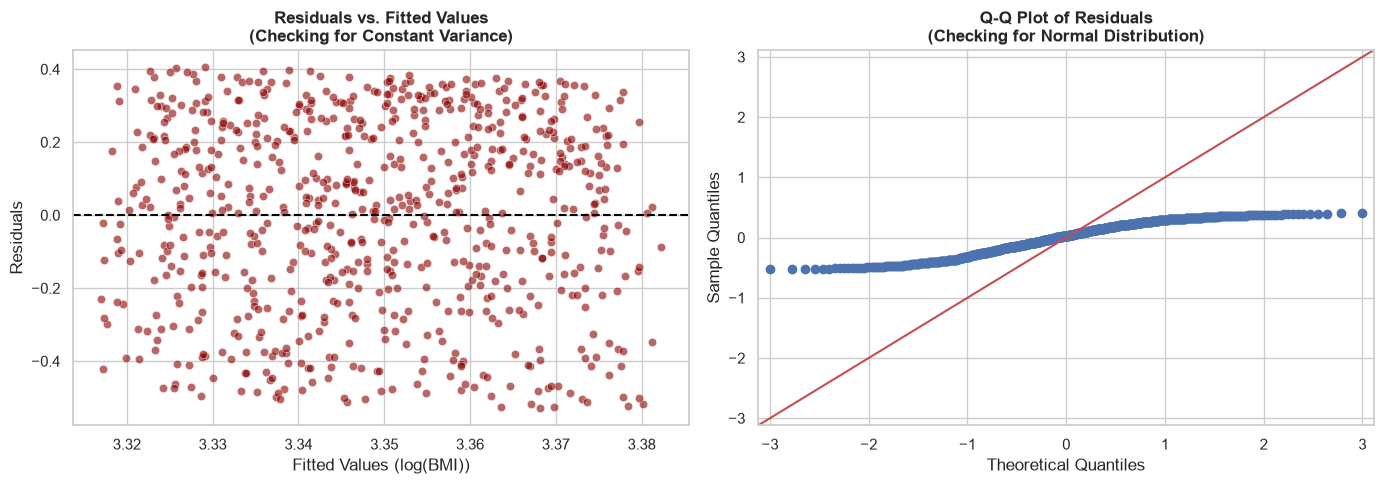

In [17]:
# ==============================================================================
# 8. RESIDUAL DIAGNOSTICS 
# ==============================================================================
# Linear regression assumes the errors (residuals) are normally distributed, not just the raw data.
# we gonna check the residuals now to be sure our transformed model is solid.
residuals = model2.resid
fitted_values = model2.fittedvalues

stat_res, p_res = stats.shapiro(residuals)
print(f"--- RESIDUAL NORMALITY CHECK ---")
print(f"Shapiro-Wilk on Residuals: Statistic = {stat_res:.4f}, p-value = {p_res:.4e}")
print("Conclusion: p > 0.05 confirms our transformed model satisfies the normality assumption.\n")

# Visualizing Residuals vs. Fitted and Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Residuals vs Fitted
# we applied scatterplot to check for homoscedasticity (constant variance)
sns.scatterplot(x=fitted_values, y=residuals, alpha=0.6, ax=axes[0], color='darkred')
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title("Residuals vs. Fitted Values\n(Checking for Constant Variance)", fontweight='bold')
axes[0].set_xlabel("Fitted Values (log(BMI))")
axes[0].set_ylabel("Residuals")

# Plot B: Q-Q Plot for Normality of Residuals
# When we use qqplot, we are telling Python to draw a straight line to see if our data points follow a normal distribution.
sm.qqplot(residuals, line='45', ax=axes[1])
axes[1].set_title("Q-Q Plot of Residuals\n(Checking for Normal Distribution)", fontweight='bold')

plt.tight_layout()
plt.show()


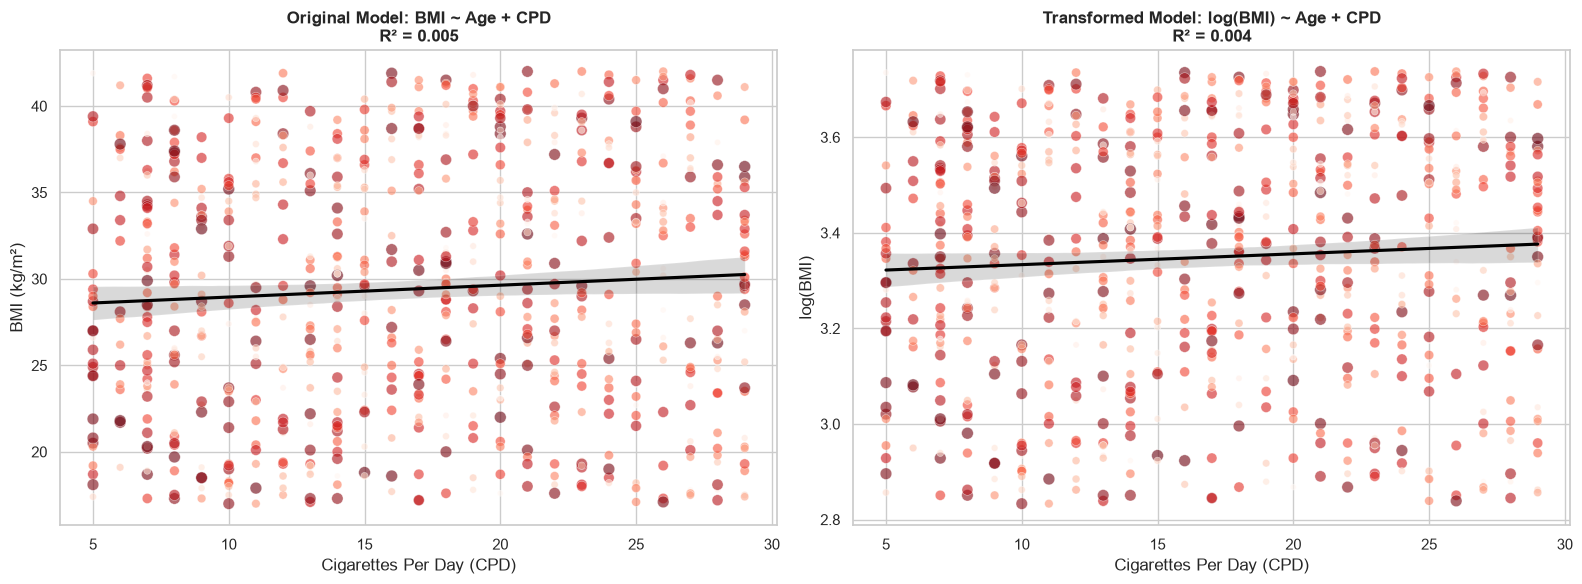

In [18]:
# ==============================================================================
# 9. VISUALIZATION: COMPARISON PLOT (Original vs Transformed)
# ==============================================================================
# this maps our primary independent and dependent variables to the coordinate axes.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Original model
# we applied scatterplot to plot the individual observations, dynamically linking both the size and color to the Age variable
sns.scatterplot(data=smokers_current, x='Cigarettes_Per_Day', y='BMI', 
                hue='Age', size='Age', palette='Reds', alpha=0.6, ax=axes[0], legend=False)
# When we use regplot with scatter=False, we are telling Python to draw a straight trend line directly through the scatter plot points.
sns.regplot(data=smokers_current, x='Cigarettes_Per_Day', y='BMI', scatter=False, color='black', ax=axes[0])
axes[0].set_title(f"Original Model: BMI ~ Age + CPD\nR² = {model1.rsquared:.3f}", fontweight='bold')
axes[0].set_xlabel("Cigarettes Per Day (CPD)")
axes[0].set_ylabel("BMI (kg/m²)")

# Plot 2: Transformed model
sns.scatterplot(data=smokers_current, x='Cigarettes_Per_Day', y='log_BMI', 
                hue='Age', size='Age', palette='Reds', alpha=0.6, ax=axes[1], legend=False)
sns.regplot(data=smokers_current, x='Cigarettes_Per_Day', y='log_BMI', scatter=False, color='black', ax=axes[1])
axes[1].set_title(f"Transformed Model: log(BMI) ~ Age + CPD\nR² = {model2.rsquared:.3f}", fontweight='bold')
axes[1].set_xlabel("Cigarettes Per Day (CPD)")
axes[1].set_ylabel("log(BMI)")

plt.tight_layout()
plt.show()

# we use plt.savefig to make the plot save easily for our github readme
# fig.savefig("model_comparison_smokers.png", dpi=300, bbox_inches='tight')


In [ ]:
# ==============================================================================
# 10. ACTUARIAL SYNTHESIS: CONNECTING REGRESSION TO CLUSTERING
# ==============================================================================
# The regression analysis revealed that Age and Cigarettes Per Day do not 
# significantly predict BMI (p > 0.05 for both predictors). 
# 
# This is a valuable actuarial finding, not a failure. It tells us that 
# morbidity risk (BMI) is driven by factors beyond smoking behavior alone 
# (like diet, exercise, and genetics).
#
# This finding validates our decision to use K-Means clustering as the 
# primary segmentation tool. Because we cannot cleanly predict BMI from 
# Age and CPD using a formula, we instead let the data reveal its own 
# natural risk groupings through unsupervised learning.
# The clustering model successfully identified two distinct tiers:
# - Tier 1: Avg Age 59, Avg CPD 11, Avg BMI 27.7 (Standard Risk)
# - Tier 2: Avg Age 50.6, Avg CPD 22.9, Avg BMI 31.2 (Substandard Risk)
# This gives the pricing team a defensible, data-driven way to assign 
# underwriting classes without relying on a weak predictive r